<a href="https://colab.research.google.com/github/zk025815-beep/ML-Foundations-From-Scratch/blob/main/Logistic_Regression_%2B_StandardScaler.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Training Accuracy: 100.00%
Learned Weights: [ 6.608 -3.573] | Learned Bias: -0.057


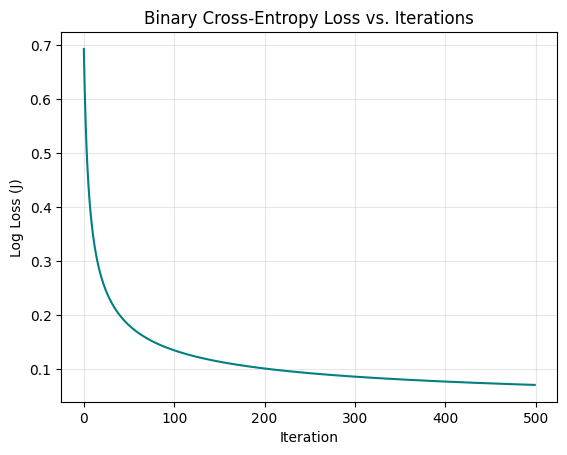

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate synthetic binary classification data (200 samples, 2 features)
np.random.seed(42)
X_raw = np.random.randn(200, 2) * 5 + np.array([10, 50]) # Unscaled features
# True boundary: 1.5*x1 - 0.8*x2 + 25 > 0
true_logits = 1.5 * X_raw[:, 0] - 0.8 * X_raw[:, 1] + 25
y = (true_logits > 0).astype(int) # Binary labels: 0 or 1

# 2. Pure NumPy StandardScaler (Mean = 0, Std = 1)
mean = np.mean(X_raw, axis=0)
std = np.std(X_raw, axis=0)
X = (X_raw - mean) / std

# 3. Helper Function: Sigmoid
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# 4. Initialize parameters
m, n = X.shape
w = np.zeros(n)
b = 0.0
learning_rate = 0.5
epochs = 500
cost_history = []

# 5. Gradient Descent Loop
for i in range(epochs):
    # Step A: Linear combination + Sigmoid activation
    z = np.dot(X, w) + b
    y_hat = sigmoid(z)

    # Step B: Binary Cross-Entropy (Log Loss) with clipping to prevent log(0)
    eps = 1e-15
    y_hat_clipped = np.clip(y_hat, eps, 1 - eps)
    cost = -(1 / m) * np.sum(y * np.log(y_hat_clipped) + (1 - y) * np.log(1 - y_hat_clipped))
    cost_history.append(cost)

    # Step C: Gradients (Exact same formula as Linear Regression!)
    dw = (1 / m) * np.dot(X.T, (y_hat - y))
    db = (1 / m) * np.sum(y_hat - y)

    # Step D: Update weights and bias
    w = w - learning_rate * dw
    b = b - learning_rate * db

# 6. Final Predictions (Threshold = 0.5)
final_probs = sigmoid(np.dot(X, w) + b)
predictions = (final_probs >= 0.5).astype(int)
accuracy = np.mean(predictions == y) * 100

print(f"Training Accuracy: {accuracy:.2f}%")
print(f"Learned Weights: {w.round(3)} | Learned Bias: {round(b, 3)}")

# Plot Log Loss Convergence
plt.plot(cost_history, color='teal')
plt.title("Binary Cross-Entropy Loss vs. Iterations")
plt.xlabel("Iteration")
plt.ylabel("Log Loss (J)")
plt.grid(True, alpha=0.3)
plt.show()